# Task 1 — Direct Preference Optimization (DPO)

This notebook is a **thin driver** around the Task 1 scripts. Every experiment is still a plain, reproducible
command (`python -m task1_dpo.train …`, `python -m task1_dpo.evaluate …`, listed in the README); the notebook
only launches them, shows **live training curves** while they run, and draws the report figures from the saved
results in `results/task1_dpo/`. Nothing depends on hidden notebook state, so you can close it at any point and
re-open it later: every cell re-reads what it needs from disk, and finished steps are skipped.

**How to use**
1. Select the repo's `.venv` Python as the kernel (VS Code: *Select Kernel → Python Environments → .venv*).
2. Run the cells top to bottom. Each step shows a live figure + the last lines of output, refreshed every ~15 s.
   The full console output of each step is saved under `results/notebook_logs/`.
3. A step whose outputs already exist is skipped. Set `FORCE = True` in the setup cell to redo everything,
   or delete that condition's folder in `outputs/task1_dpo/` and `results/task1_dpo/`.
4. The stop button kills the running script cleanly; re-running the cell starts that step again.

| Step | What it runs | Rough time on an RTX 5060 laptop (estimate) |
|---|---|---|
| 0 | objective unit tests + 32-pair GPU smoke run | 2–3 min |
| 1 | standard DPO, 1 epoch on the 1,500 standard pairs | 30–60 min |
| 2 | evaluate SFT baseline and standard DPO | ~10–15 min each |
| 3 | β ∈ {0.03, 0.10, 0.30} short forks (600 pairs each) + evaluation | ~1–1.5 h |
| 4 | length-balanced DPO + length-stratified evaluation | ~45–60 min |
| 5 | summary tables, report figures (`report/figures/`), qualitative candidates | seconds |

In [1]:
# --- setup ---------------------------------------------------------------------------------------
import os, sys, shutil
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "configs").exists() and ROOT.parent != ROOT:   # works from the repo root or task1_dpo/
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import torch
from IPython.display import display, Markdown
from common.data import load_yaml, repo_path
from common.live import run_live
from task1_dpo import plots

CONFIG = os.environ.get("PA2_DPO_CONFIG", "configs/dpo.yaml")
FORCE = False          # True = retrain / re-evaluate even if outputs exist
cfg = load_yaml(CONFIG)
RES = repo_path(cfg["results_dir"])
BETAS = [float(b) for b in cfg["betas"]]

def done(path):
    return (not FORCE) and repo_path(path).exists()

print("repo root :", ROOT)
print("python    :", sys.executable)
if ".venv" not in sys.executable:
    print("WARNING: this kernel is not the repo's .venv Python - select the .venv kernel before running.")
print("torch     :", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")
print("config    :", CONFIG, "| beta =", cfg["beta"], "| betas =", BETAS,
      "| batch", cfg["batch_size"], "x accum", cfg["grad_accum_steps"])
pd.set_option("display.max_colwidth", 120)

repo root : D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining
python    : d:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\.venv\Scripts\python.exe
torch     : 2.11.0+cu128 | CUDA: True | NVIDIA GeForce RTX 5060 Laptop GPU
config    : configs/dpo.yaml | beta = 0.1 | betas = [0.03, 0.1, 0.3] | batch 2 x accum 8


## Step 0 — validate the objectives, then a short GPU smoke run

The unit tests check the corrected DPO, PPO and GRPO objectives against values worked out by hand
(see `scripts/test_objectives.py`). The smoke run trains on 32 pairs to confirm the training loop fits in GPU
memory before committing to the long runs; its outputs are deleted afterwards so they never reach `results/`.

In [2]:
run_live("scripts.test_objectives", title="Objective unit tests", refresh_s=1)

Objective unit tests
FINISHED OK  |  elapsed 0m02s  |  full log: D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\notebook_logs\scripts_test_objectives.log

PASS  test_dpo_at_initialisation_is_log2
PASS  test_dpo_matches_manual_formula
PASS  test_dpo_gradient_direction
PASS  test_ppo_clip_positive_advantage
PASS  test_ppo_clip_negative_advantage
PASS  test_ppo_inside_trust_region_is_unclipped
PASS  test_ppo_mask_ignores_padding
PASS  test_gae_terminal_reward
PASS  test_grpo_advantages_are_per_group
PASS  test_grpo_advantages_invariant_to_other_groups
PASS  test_grpo_loss_normalisations
11/11 passed


GPU smoke run (32 pairs)
FINISHED OK  |  elapsed 0m54s  |  full log: D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\notebook_logs\task1_dpo_train.log



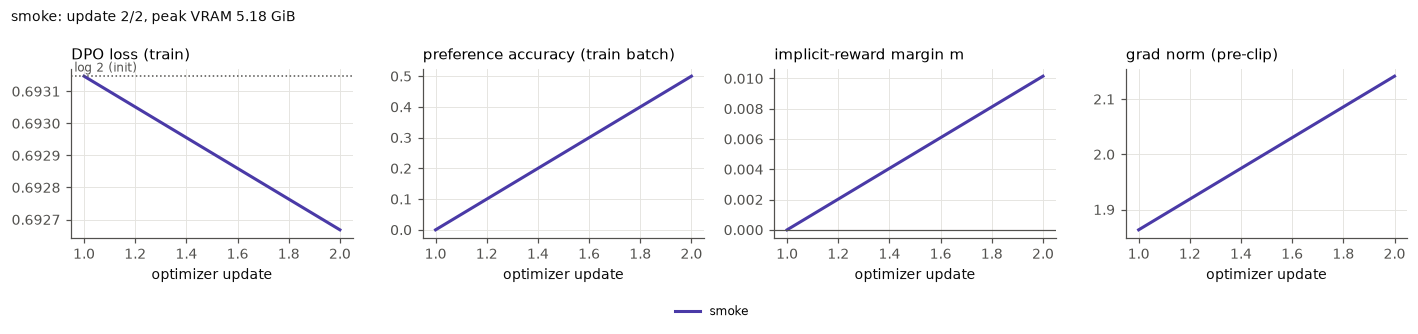

W1008 01:59:38.586000 2512 .venv\Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
[smoke] 29 pairs (3 dropped for long prompts), beta=0.1, 15 micro-batches/epoch, 2 optimizer updates
[smoke] update 1/2 loss=0.6931 acc=0.000 margin=0.000 |g|=1.863 t=12s eta=0.2min
[smoke] update 2/2 loss=0.6927 acc=0.500 margin=0.010 |g|=2.142 t=24s eta=0.0min
[smoke] saved adapter to D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\outputs\task1_dpo\smoke (0.4 min)

Smoke run OK: peak VRAM 5.176 GiB, 24.2 s


In [3]:
SMOKE_MARK = repo_path("outputs/task1_dpo/.smoke_ok")
if SMOKE_MARK.exists() and not FORCE:
    print("Smoke run already passed earlier - skipping.")
else:
    try:
        run_live("task1_dpo.train", "--config", CONFIG, "--run-name", "smoke", "--max-examples", 32,
                 "--output", "outputs/task1_dpo/smoke", title="GPU smoke run (32 pairs)",
                 plot_fn=lambda: plots.train_curves(cfg, ["smoke"], smooth=1), refresh_s=5)
        summary = plots._json(RES / "smoke" / "train_summary.json")
        print(f"\nSmoke run OK: peak VRAM {summary['peak_vram_gib']} GiB, {summary['wall_clock_s']} s")
        SMOKE_MARK.parent.mkdir(parents=True, exist_ok=True)
        SMOKE_MARK.write_text("ok")
    finally:
        shutil.rmtree(RES / "smoke", ignore_errors=True)
        shutil.rmtree(repo_path("outputs/task1_dpo/smoke"), ignore_errors=True)

## Step 1 — standard DPO (one epoch)

Fresh LoRA on Qwen2.5-1.5B-Instruct, β = 0.1, the full standard preference file, one epoch. The reference
policy is the same network with the LoRA adapter disabled. Each optimizer update is logged to
`results/task1_dpo/standard/train_log.jsonl`; the figure below is drawn from that file.
At initialization the loss must sit at log 2 ≈ 0.693 and the margin at 0.

Standard DPO, 1 epoch
FINISHED OK  |  elapsed 17m15s  |  full log: D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\notebook_logs\task1_dpo_train.log



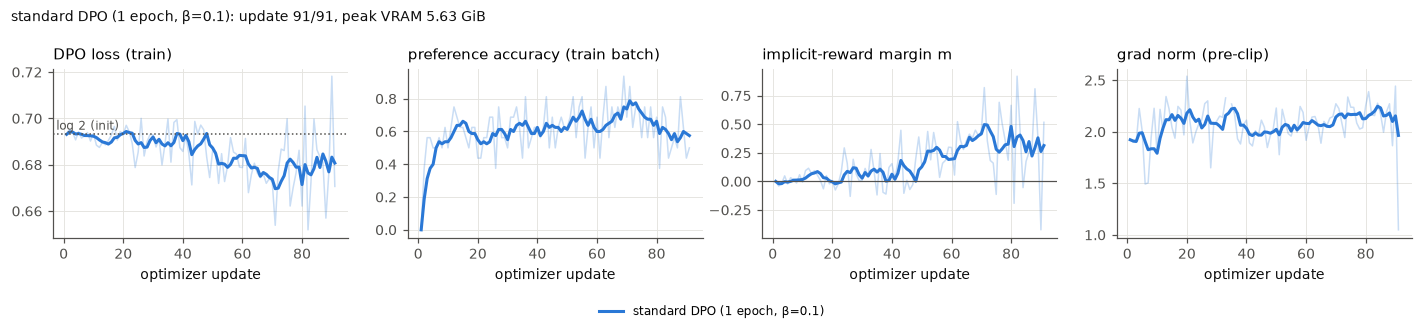

[standard] update 15/91 loss=0.6905 acc=0.625 margin=0.054 |g|=2.042 t=163s eta=13.7min
[standard] update 20/91 loss=0.6932 acc=0.438 margin=0.004 |g|=2.540 t=218s eta=12.9min
[standard] update 25/91 loss=0.6855 acc=0.688 margin=0.158 |g|=2.116 t=275s eta=12.1min
[standard] update 30/91 loss=0.6929 acc=0.500 margin=0.010 |g|=2.103 t=333s eta=11.3min
[standard] update 35/91 loss=0.6997 acc=0.438 margin=-0.118 |g|=2.270 t=392s eta=10.5min
[standard] update 40/91 loss=0.6858 acc=0.625 margin=0.156 |g|=2.113 t=450s eta=9.6min
[standard] update 45/91 loss=0.6932 acc=0.688 margin=0.010 |g|=2.113 t=504s eta=8.6min
[standard] update 50/91 loss=0.6862 acc=0.625 margin=0.144 |g|=2.231 t=557s eta=7.6min
[standard] update 55/91 loss=0.6794 acc=0.812 margin=0.281 |g|=1.959 t=613s eta=6.7min
[standard] update 60/91 loss=0.6788 acc=0.688 margin=0.297 |g|=1.918 t=667s eta=5.7min
[standard] update 65/91 loss=0.6764 acc=0.750 margin=0.355 |g|=1.889 t=722s eta=4.8min
[standard] update 70/91 loss=0.6725 a

run_name                                                                                 standard
updates                                                                                        91
wall_clock_s                                                                               1017.8
peak_vram_gib                                                                               5.633
adapter          D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\outputs\task1_dpo\standard
dtype: object

In [4]:
if done("outputs/task1_dpo/standard/adapter_model.safetensors"):
    print("Standard adapter exists - skipping training (set FORCE = True to retrain).")
    display(plots.train_curves(cfg, ["standard"]))
else:
    run_live("task1_dpo.train", "--config", CONFIG, "--run-name", "standard",
             title="Standard DPO, 1 epoch", plot_fn=lambda: plots.train_curves(cfg, ["standard"]))
display(pd.Series(plots._json(RES / "standard" / "train_summary.json")))

## Step 2 — evaluate the SFT baseline and standard DPO

Held-out pairs: DPO loss, preference accuracy (fraction of pairs with implicit-reward margin m > 0, 95% bootstrap CI).
Generations on the held-out prompts (identical prompts, order, seed and sampling settings for every condition):
sampled-token KL from the reference, reward-model score, entropy, response length; plus word-limit compliance on
the 10 common prompts (5 samples each). For SFT the policy *is* the reference, so its margin, accuracy and KL are 0 by
construction — it serves as the reward/length baseline.

In [5]:
for name, adapter in [("sft", "none"), ("standard", "outputs/task1_dpo/standard")]:
    if done(f"{cfg['results_dir']}/{name}/eval_dpo_standard_eval.json"):
        print(f"{name}: evaluation exists - skipping.")
    else:
        run_live("task1_dpo.evaluate", "--config", CONFIG, "--adapter", adapter, "--name", name,
                 title=f"Evaluate {name}", refresh_s=10)

Evaluate standard
FINISHED OK  |  elapsed 7m24s  |  full log: D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\notebook_logs\task1_dpo_evaluate.log

[eval:standard] generation batch 7/17 (91s elapsed)
[eval:standard] generation batch 8/17 (105s elapsed)
[eval:standard] generation batch 9/17 (124s elapsed)
[eval:standard] generation batch 10/17 (138s elapsed)
[eval:standard] generation batch 11/17 (154s elapsed)
[eval:standard] generation batch 12/17 (169s elapsed)
[eval:standard] generation batch 13/17 (184s elapsed)
[eval:standard] generation batch 14/17 (199s elapsed)
[eval:standard] generation batch 15/17 (214s elapsed)
[eval:standard] generation batch 16/17 (231s elapsed)
[eval:standard] generation batch 17/17 (247s elapsed)
[eval:standard:word-limit] generation batch 1/4 (0s elapsed)
[eval:standard:word-limit] generation batch 2/4 (4s elapsed)
[eval:standard:word-limit] generation batch 3/4 (11s elapsed)
[eval:standard:word-limit] generation batch 4/4 (17s elapsed)
[r

## Step 3 — regularization-strength study (β forks)

Three short runs from the original initialization with β ∈ {0.03, 0.10, 0.30}: same first
`short_ablation_examples` pairs, same seed, shuffle order, optimizer and LoRA config — only β changes.
Each fork is then evaluated with the identical protocol. `task1_dpo.ablate_beta` skips forks that are already done.

β study: train + evaluate forks
FINISHED OK  |  elapsed 1h33m55s  |  full log: D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\notebook_logs\task1_dpo_ablate_beta.log



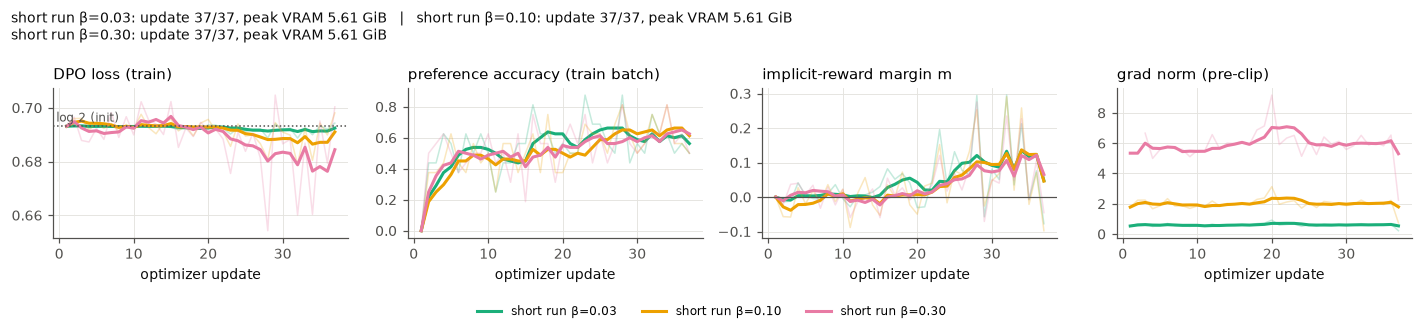

[eval:beta_0.3] generation batch 8/17 (104s elapsed)
[eval:beta_0.3] generation batch 9/17 (119s elapsed)
[eval:beta_0.3] generation batch 10/17 (134s elapsed)
[eval:beta_0.3] generation batch 11/17 (150s elapsed)
[eval:beta_0.3] generation batch 12/17 (164s elapsed)
[eval:beta_0.3] generation batch 13/17 (179s elapsed)
[eval:beta_0.3] generation batch 14/17 (194s elapsed)
[eval:beta_0.3] generation batch 15/17 (209s elapsed)
[eval:beta_0.3] generation batch 16/17 (226s elapsed)
[eval:beta_0.3] generation batch 17/17 (242s elapsed)
[eval:beta_0.3:word-limit] generation batch 1/4 (0s elapsed)
[eval:beta_0.3:word-limit] generation batch 2/4 (4s elapsed)
[eval:beta_0.3:word-limit] generation batch 3/4 (10s elapsed)
[eval:beta_0.3:word-limit] generation batch 4/4 (16s elapsed)
[reward] scoring 272 responses with the reward model
[eval:beta_0.3] gen: reward=1.298 kl_tok=-0.0003 len=157.8±104.5 word-limit=0.62
[eval:beta_0.3] wrote D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\result

In [6]:
fork_names = [f"beta_{b:g}" for b in BETAS]
run_live("task1_dpo.ablate_beta", "--config", CONFIG, title="β study: train + evaluate forks",
         plot_fn=lambda: plots.train_curves(cfg, fork_names))

## Step 4 — length-confounding study

Trains one more model on the supplied length-balanced file (equal numbers of preferred-longer, length-matched and
rejected-longer pairs), then evaluates both the standard and the length-balanced model on the length-stratified
held-out set, and the length-balanced model on the common prompt set (generated length, word-limit compliance).

Length study
FINISHED OK  |  elapsed 23m40s  |  full log: D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\notebook_logs\task1_dpo_analyze_length.log



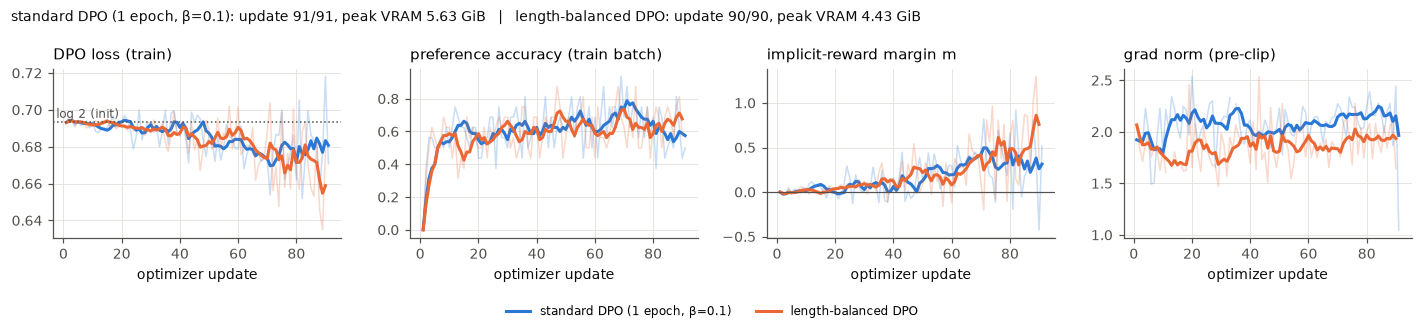

[eval:standard] pairs: acc=0.557 loss=0.6821 margin=0.279
[eval:standard] wrote D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\task1_dpo\standard\eval_dpo_length_stratified_eval.json (1.3 min)
>>> d:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\.venv\Scripts\python.exe -m task1_dpo.evaluate --config configs/dpo.yaml --adapter outputs/task1_dpo/length_balanced --name length_balanced --eval-file dpo_length_eval --no-generate
W1008 04:30:15.546000 5540 .venv\Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
[eval:length_balanced] adapter=outputs/task1_dpo/length_balanced eval_file=data/dpo_length_stratified_eval.jsonl (246 pairs)
[pairs] batch 1/60
[pairs] batch 11/60
[pairs] batch 21/60
[pairs] batch 31/60
[pairs] batch 41/60
[pairs] batch 51/60
[eval:length_balanced] pairs: acc=0.620 loss=0.6759 margin=0.444
[eval:length_balanced] wrote D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\results\task

In [7]:
run_live("task1_dpo.analyze_length", "--config", CONFIG, title="Length study",
         plot_fn=lambda: plots.train_curves(cfg, ["standard", "length_balanced"]))

## Step 5 — results

Summary tables are recomputed from the saved per-condition JSON files (cheap), then the figures are drawn and saved to
`report/figures/`. Note that the one-epoch standard run and the short β forks use **different training budgets**
(the `budget` column) — compare forks with each other, and the standard run separately.

In [8]:
import subprocess
for module in ("task1_dpo.ablate_beta", "task1_dpo.analyze_length"):
    subprocess.run([sys.executable, "-m", module, "--config", CONFIG, "--summary-only"], cwd=ROOT, check=False,
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

if (RES / "summary_beta.csv").exists():
    beta_tbl = pd.read_csv(RES / "summary_beta.csv")
    cols = ["condition", "budget", "beta", "optimizer_updates", "heldout_dpo_loss", "heldout_pref_acc",
            "kl_token_mean", "kl_seq_mean", "reward_mean", "entropy_mean", "len_mean", "len_std", "len_iqr",
            "truncation_rate", "word_limit_compliance"]
    display(Markdown("**DPO summary (standard run, β forks, SFT reference)**"))
    display(beta_tbl[[c for c in cols if c in beta_tbl]].round(4))
if (RES / "summary_length.json").exists():
    s = plots._json(RES / "summary_length.json")
    display(Markdown("**Length profile of the preference data (a property of the dataset, not the policy)**"))
    display(pd.DataFrame(s["dataset_length_profile"]).T.drop(columns=["file"], errors="ignore"))
    display(Markdown("**Standard vs length-balanced DPO**"))
    display(pd.DataFrame(s["models"]).set_index("condition").T.round(4))

**DPO summary (standard run, β forks, SFT reference)**

,condition,budget,beta,optimizer_updates,heldout_dpo_loss,heldout_pref_acc,kl_token_mean,kl_seq_mean,reward_mean,entropy_mean,len_mean,len_std,len_iqr,truncation_rate,word_limit_compliance
0,sft,none (reference policy),NaN,NaN,0.6931,0.0000,0.0000,0.0000,1.2784,0.8744,158.3860,105.2214,216.25,0.4632,0.62
1,standard,"1 epoch, full standard set",0.10,91.0,0.6735,0.6414,0.0001,0.0236,1.2839,0.8912,158.8750,104.9037,216.25,0.4743,0.44
2,beta_0.03,"short run, first 600 pairs",0.03,37.0,0.6914,0.6483,-0.0003,-0.0476,1.3139,0.8774,156.9706,104.2831,215.25,0.4596,0.62
3,beta_0.1,"short run, first 600 pairs",0.10,37.0,0.6875,0.6517,-0.0003,-0.0487,1.3019,0.8691,158.4228,104.3639,215.25,0.4559,0.60
4,beta_0.3,"short run, first 600 pairs",0.30,37.0,0.6788,0.6483,-0.0003,-0.0482,1.2983,0.8674,157.8346,104.5448,213.50,0.4596,0.62


**Length profile of the preference data (a property of the dataset, not the policy)**

,n_pairs,frac_chosen_longer,mean_len_diff_chosen_minus_rejected,median_len_diff,strata_counts
standard_train,1500,0.562667,42.45,18.0,NaN
length_balanced_train,1500,0.491333,5.163333,0.0,"{'length_matched': 500, 'preferred_longer': 500, 'rejected_longer': 500}"
standard_eval,300,0.533333,30.646667,5.0,NaN
length_stratified_eval,246,0.48374,2.695122,-0.5,"{'length_matched': 82, 'preferred_longer': 82, 'rejected_longer': 82}"


**Standard vs length-balanced DPO**

condition,standard,length_balanced,sft
strat_overall_acc,0.5570,0.6203,NaN
acc_length_matched,0.5625,0.5750,NaN
acc_length_matched_ci_lo,0.4625,0.4625,NaN
acc_length_matched_ci_hi,0.6625,0.6875,NaN
margin_length_matched,0.2045,0.3314,NaN
n_length_matched,80.0000,80.0000,NaN
acc_preferred_longer,0.4615,0.4872,NaN
acc_preferred_longer_ci_lo,0.3590,0.3718,NaN
acc_preferred_longer_ci_hi,0.5772,0.6026,NaN
margin_preferred_longer,-0.1016,-0.4535,NaN


saved D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\report\figures\task1_training_curves.png


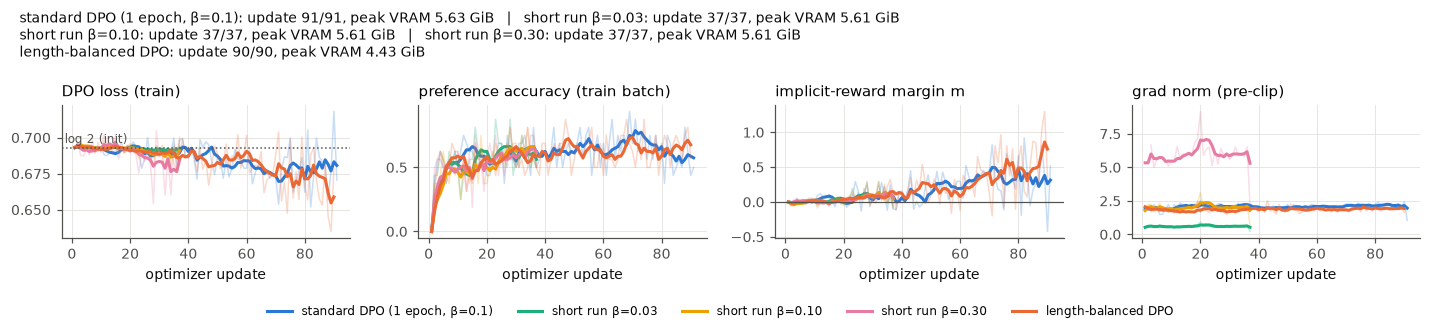

saved D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\report\figures\task1_beta_study.png


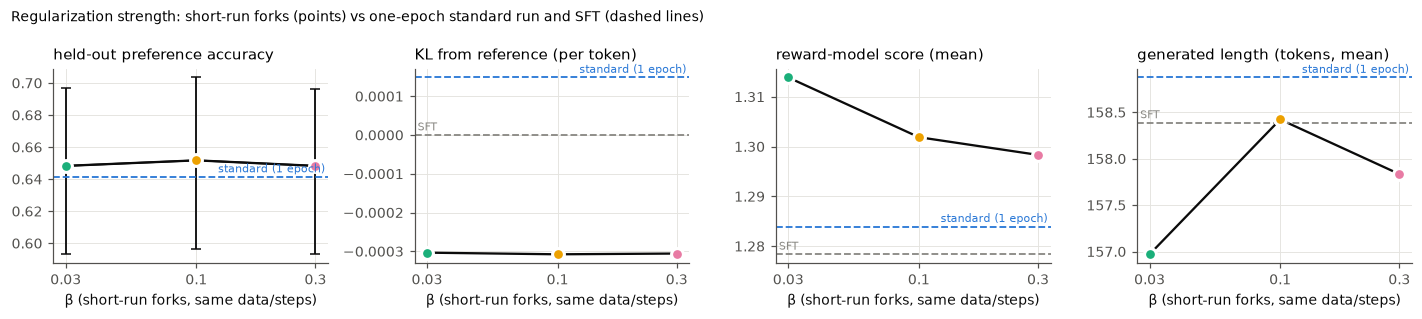

saved D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\report\figures\task1_length_strata.png


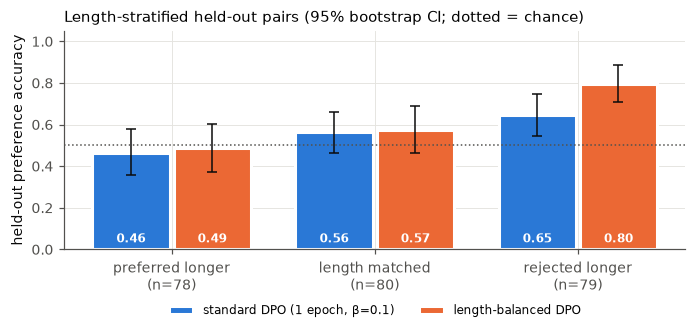

saved D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\report\figures\task1_generated_length.png


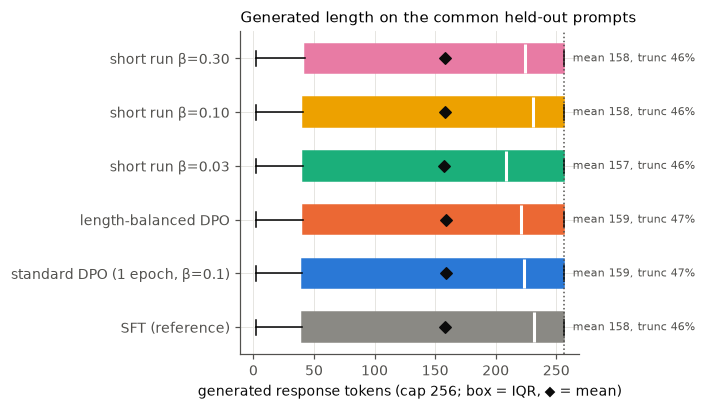

saved D:\Junior\CS6304 - ATML\PA2\ATML-PA2-LLM-PostTraining\report\figures\task1_word_limit.png


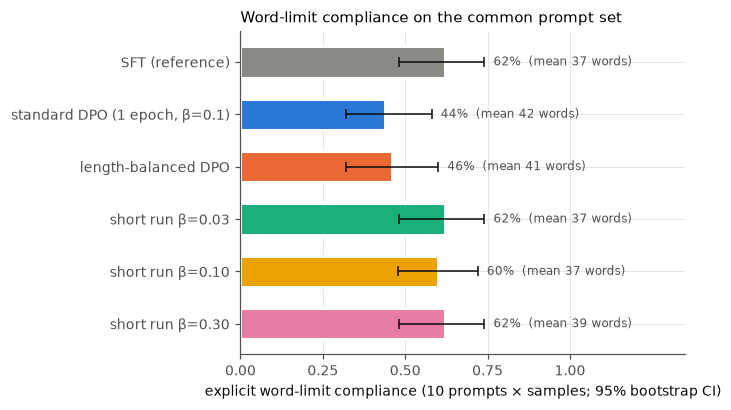

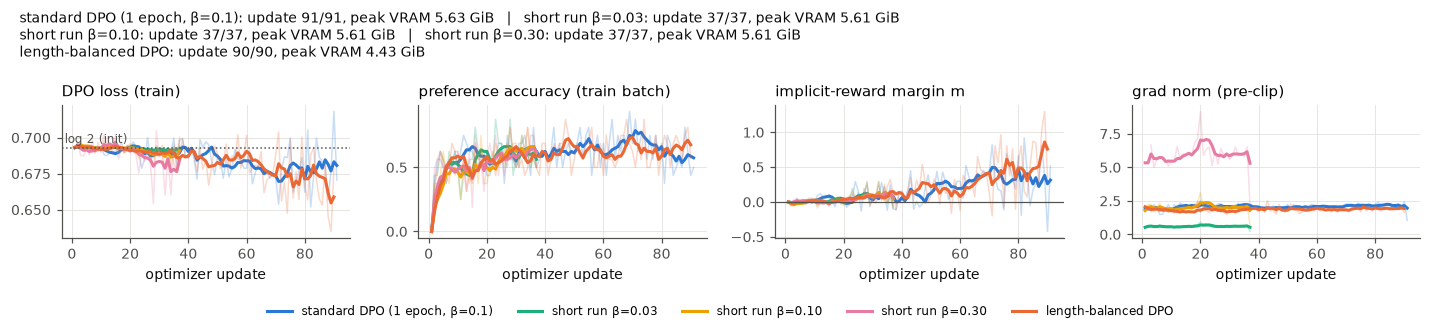

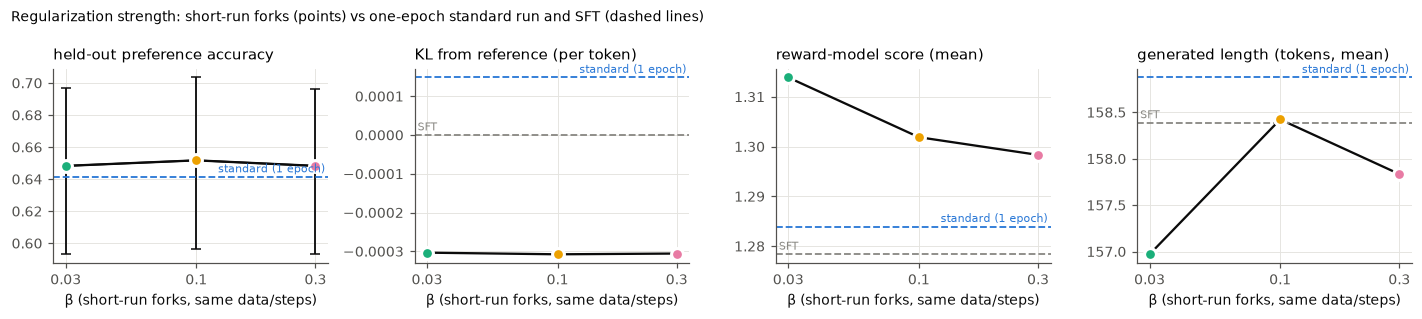

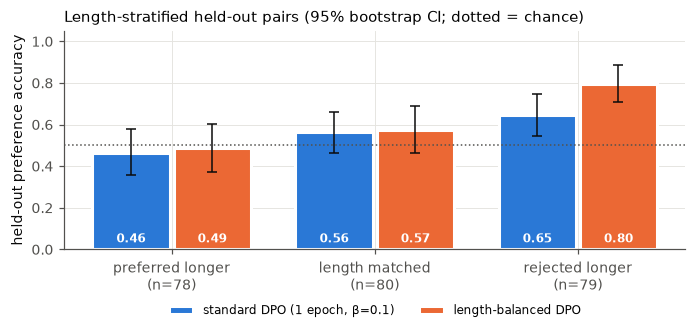

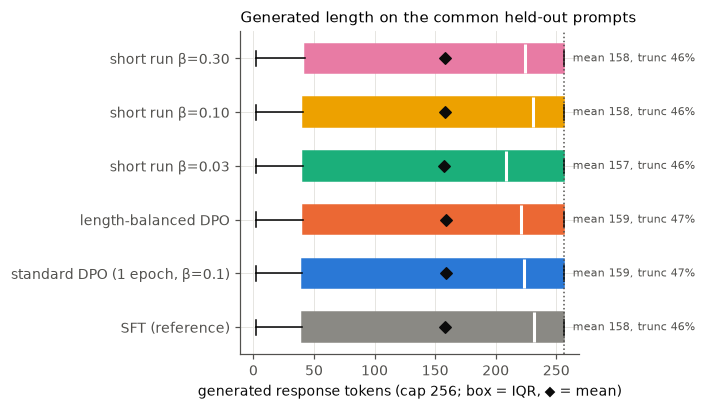

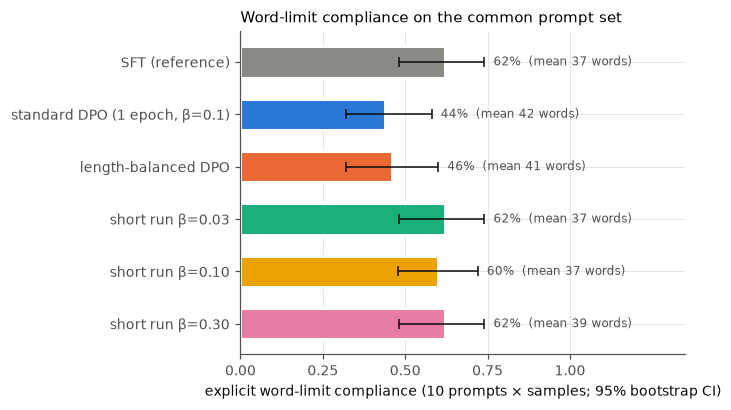

In [9]:
figs = {
    "task1_training_curves": plots.train_curves(cfg, ["standard", *fork_names, "length_balanced"]),
    "task1_beta_study": plots.beta_study(cfg),
    "task1_length_strata": plots.length_strata(cfg),
    "task1_generated_length": plots.generated_lengths(cfg),
    "task1_word_limit": plots.word_limit(cfg),
}
for name, fig in figs.items():
    plots.save(fig, name)
    if fig is not None:
        display(fig)

## Step 6 — qualitative candidates

The report needs brief examples of (i) a preference/reward signal that disagrees with response quality and
(ii) length-bias or instruction-compliance behaviour. The tables below only **surface candidates** from the saved
generations; read them and judge correctness, concision and instruction-following yourself before quoting any.
Change `k` or the condition names to look further.

In [10]:
display(Markdown("**Largest reward gains of standard DPO over SFT on the same prompt** (check: is the higher-reward answer actually better, or just longer / truncated?)"))
display(plots.reward_vs_quality_candidates(cfg, policy="standard", base="sft", k=5))

**Largest reward gains of standard DPO over SFT on the same prompt** (check: is the higher-reward answer actually better, or just longer / truncated?)

,prompt_id,reward_gain,len_policy,len_base,truncated_policy,prompt,standard_response,sft_response,len_ratio
32,8877f25cf9d6c6665ce92d44de7864742a5d46a2ece0409749bb3c905a5be65d,2.720703,256,256,True,wordpress cors error fix for nextjs,"To resolve Cross-Origin Resource Sharing (CORS) issues in WordPress when integrated with Next.js, you can follow the...","To resolve Cross-Origin Resource Sharing (CORS) issues in WordPress when integrated with Next.js, you can follow the...",1.000000
25,13450688a9905b010b72cc491d8610b5588c3cacaed0bb30aa6b7c8a2b715aa5,2.458618,32,24,False,"In this task, you are given a question and a corresponding answer. Your task is to generate a fact statement that is...","Songbirds prefer seed-based food sources in their yards. Therefore, hanging an open box filled with nutritious birds...",Songbirds prefer open spaces with plenty of food sources near trees or other structures where they can easily spot p...,1.333333
80,6d41333fcd38e4b75efab869b10d54566e58e989a91e541828b7bb3f558ca008,2.257812,256,256,True,"Create a lightning component in Aura & LWC both, in Dev org to showcase table of contact records - All contacts reco...",To create a Lightning Component (LWC) and an Aura Component that lists Contact records from a selected Account and a...,To create a Lightning Component (LWC) and an Aura Component that lists Contact records from a selected Account and a...,1.000000
97,aca585934d139c0ea4abcffd29c3fb6e99734fc603450d06b12701f77545bb21,2.049805,256,256,True,"""Create a themed gift basket for a book lover that includes books from different genres, bookmarks, a reading lamp, ...","**Gift Basket Theme: ""Book Haven Bliss""** --- ### **1. Books** - 2 Hardback Fiction Novels (e.g., ""The Great Gatsby""...","**Gift Basket Theme: ""Wanderlust Wonders""** --- ### **Introduction** Welcome to the ""Wanderlust Wonders"" Gift Basket...",1.000000
197,942295e72dc5560783d359f1a830d8b457caa3966b18a56dcfdfcab17ee0cd0d,1.895264,256,256,True,Examine the impact of technological advances on the beauty industry and evaluate how salons and spas are adapting to...,The impact of technological advancements on the beauty industry is significant and multifaceted. Here's an examinati...,The impact of technological advancements on the beauty industry is significant and multifaceted. Here's an examinati...,1.000000


In [11]:
display(Markdown("**Word-limit violations by standard DPO** (largest overshoot first)"))
display(plots.word_limit_failures(cfg, policy="standard", k=5))
display(Markdown("**Rejected-longer held-out pairs where standard and length-balanced DPO disagree**"))
display(plots.stratum_flips(cfg, stratum="rejected_longer", k=5))

**Word-limit violations by standard DPO** (largest overshoot first)

,prompt_id,limit,words,prompt,response
0,wl05,45,109,Describe one advantage and one limitation of attention in at most 45 words.,Attention is an effective mechanism for focusing on relevant information while filtering out irrelevant data during ...
1,wl10,45,91,Explain what a frozen reference model does in RLHF in at most 45 words.,"In Reinforcement Learning with Human Feedback (RLHF), a frozen reference model refers to a fixed policy or neural ne..."
2,wl10,45,89,Explain what a frozen reference model does in RLHF in at most 45 words.,A frozen reference model (FRM) in Reinforcement Learning with Human Feedback (RLHF) is an approach where the reward ...
3,wl07,35,65,Explain the role of a learning rate in at most 35 words.,A learning rate determines how much to adjust the model parameters during training; it controls the step size for up...
4,wl07,35,64,Explain the role of a learning rate in at most 35 words.,A learning rate is a hyperparameter that determines how much to adjust the model's weights during training. A high l...


**Rejected-longer held-out pairs where standard and length-balanced DPO disagree**

,prompt_id,standard_margin,length_balanced_margin,chosen_tokens,rejected_tokens
6,387350f4ede9b8e36bed24abd70469cf57f4e5a76f5e9a2db1d3e2c5ce2ed648,-0.087303,1.580048,178,307
1,801c7a49a40bfe05b462600464f5c679ea51d60a9682ca95fc5ac02382b7d032,-0.252365,0.727608,88,119
2,96c539af8e17f6cd3cbfb757c3f14bab6941a45bebe3c08cce71a4fd97d83c1f,-0.178474,0.676910,29,91
7,9c5554433c25d0d360bece8bc3bb9223fc87380efc49b7e95cbda1ed6428d0f1,-0.153961,0.352310,111,249
8,b851ec8e8dbed26c2754462b43f4df84d6e9968c4114523583bc421be075f23f,-0.362595,0.350311,182,319


In [12]:
# Look up the full text of any pair or generation by prompt_id
def show_pair(prompt_id, eval_file="dpo_standard_eval"):
    from common.data import read_jsonl, preference_responses
    for r in read_jsonl(cfg["paths"][eval_file]):
        if r["prompt_id"] == prompt_id:
            yc, yr = preference_responses(r)
            display(Markdown(f"**Prompt**\n\n{r['prompt']}\n\n**Chosen**\n\n{yc}\n\n**Rejected**\n\n{yr}"))
            return
    print("not found")

def show_generation(prompt_id, conditions=("sft", "standard", "length_balanced")):
    for c in conditions:
        for r in plots.read_jsonl_safe(RES / c / "generations.jsonl"):
            if r["prompt_id"] == prompt_id:
                display(Markdown(f"**{c}** — reward {r['reward']:.2f}, {r['response_tokens']} tokens"
                                 f"{' (truncated)' if r['truncated'] else ''}\n\n{r['response']}"))

# example: show_generation("<prompt_id from a table above>")